# Normalização por landmarks — celebahq_pp (item 1)

Segunda passada de alinhamento sobre `celebahq_pp` (já 224×224 via `norm_crop`).
Detecta 5 landmarks com `models/face_detector.py` (SCRFD) e aplica similaridade
a um template de destino 224×224.

**Templates disponíveis** (trocar via `TEMPLATE_NAME` na célula de setup):

| Nome | Uso | Enquadramento |
|------|-----|----------------|
| `arcface` (**default**) | pipeline deste projeto | InsightFace `arcface_dst` ×2 — mesmo do `norm_crop` |
| `visual` | comparação / futuro grupo de template visual | face mais alta/maior (pipeline externo 112×112 escalado) |

**Fluxo:** (1) validar 3 exemplos com o template escolhido → (2) seção opcional
comparando `arcface` vs `visual` lado a lado → (3) só então rodar o batch.

Saída default: `/mnt/study-data/dcarvalho/datasets/celebahq_pp_norm`  
Saída `visual`: `/mnt/study-data/dcarvalho/datasets/celebahq_pp_norm_visual`

A seção LFW (item 2) pode reutilizar os helpers abaixo.


In [1]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from insightface.utils.face_align import arcface_dst

from models.face_detector import (
    LANDMARK_NAMES,
    _to_bgr_uint8,
    get_default_detector,
)

INPUT_DIR = Path("/mnt/study-data/dcarvalho/datasets/celebahq_pp")
IMAGE_SIZE = 224
JPEG_QUALITY = 95
DET_THRESH = 0.5
CTX_ID = 0  # 0 = GPU; -1 = CPU

assert IMAGE_SIZE % 112 == 0, "IMAGE_SIZE deve ser múltiplo de 112 (ArcFace)"

# --- Templates (ordem LE, RE, N, LM, RM) ---
TEMPLATES = {
    # Oficial InsightFace — mesmo destino do norm_crop (olhos ~y=103 em 224)
    "arcface": (arcface_dst * (IMAGE_SIZE / 112.0)).astype(np.float32),
    # Pipeline externo de template visual (face mais alta/maior no canvas)
    "visual": np.array(
        [
            [68.88772, 67.83798],
            [152.22427, 67.85162],
            [110.30249, 110.07262],
            [75.59366, 155.83430],
            [146.31252, 155.63870],
        ],
        dtype=np.float32,
    ),
}

OUT_DIRS = {
    "arcface": Path("/mnt/study-data/dcarvalho/datasets/celebahq_pp_norm"),
    "visual": Path("/mnt/study-data/dcarvalho/datasets/celebahq_pp_norm_visual"),
}

# Troque para "visual" para experimentar o outro enquadramento
TEMPLATE_NAME = "arcface"
assert TEMPLATE_NAME in TEMPLATES, f"TEMPLATE_NAME inválido: {TEMPLATE_NAME}"

SRC_TEMPLATE = TEMPLATES[TEMPLATE_NAME]
OUT_DIR = OUT_DIRS[TEMPLATE_NAME]

VALID_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

print(f"Entrada: {INPUT_DIR}")
print(f"TEMPLATE_NAME={TEMPLATE_NAME}")
print(f"Saída:   {OUT_DIR}")
print(f"Template SRC:\n{SRC_TEMPLATE}")
print(f"size={IMAGE_SIZE}")
print(f"Templates disponíveis: {list(TEMPLATES)}")


/home/dcarvalho/Lightweight-Face-De-identification/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Entrada: /mnt/study-data/dcarvalho/datasets/celebahq_pp
TEMPLATE_NAME=arcface
Saída:   /mnt/study-data/dcarvalho/datasets/celebahq_pp_norm
Template SRC:
[[ 76.5892 103.3926]
 [147.0636 103.0028]
 [112.0504 143.4732]
 [ 83.0986 184.731 ]
 [141.4598 184.4082]]
size=224
Templates disponíveis: ['arcface', 'visual']


## Helpers (reutilizáveis na tarefa 2 / LFW)


In [2]:
def ensure_bgr(image):
    """Converte path/PIL via face_detector; ndarray uint8 HxWx3 já é BGR."""
    if isinstance(image, np.ndarray):
        arr = image
        if arr.dtype != np.uint8:
            if arr.max() <= 1.0:
                arr = (arr * 255.0).clip(0, 255).astype(np.uint8)
            else:
                arr = arr.clip(0, 255).astype(np.uint8)
        if arr.ndim != 3 or arr.shape[2] != 3:
            raise ValueError(f"Esperado HxWx3 BGR, recebido shape={arr.shape}")
        return np.ascontiguousarray(arr)
    return _to_bgr_uint8(image)


def resolve_template(template=None):
    """Aceita None (usa SRC_TEMPLATE), nome em TEMPLATES, ou array (5,2)."""
    if template is None:
        return SRC_TEMPLATE, TEMPLATE_NAME
    if isinstance(template, str):
        if template not in TEMPLATES:
            raise KeyError(f"Template desconhecido: {template!r}. Use {list(TEMPLATES)}")
        return TEMPLATES[template], template
    pts = np.asarray(template, dtype=np.float32).reshape(5, 2)
    return pts, "custom"


def align_to_template(
    image,
    detector,
    *,
    template=None,
    image_size: int = IMAGE_SIZE,
    border_mode=cv2.BORDER_CONSTANT,
    border_value=0.0,
):
    """Detecta 5 landmarks e aplica similaridade ao template de destino.

    Returns:
        ((aligned_bgr, landmarks_before, landmarks_after, template_pts), None)
        em sucesso, ou (None, reason) com reason in {"no_face", "affine_failed"}.
    """
    dst, _name = resolve_template(template)
    bgr = ensure_bgr(image)
    result = detector.detect_best(bgr)
    if result is None:
        return None, "no_face"

    landmarks_before = result.landmarks.astype(np.float32)
    M, _inliers = cv2.estimateAffinePartial2D(
        landmarks_before,
        dst,
        method=cv2.LMEDS,
    )
    if M is None:
        return None, "affine_failed"

    aligned = cv2.warpAffine(
        bgr,
        M,
        (image_size, image_size),
        flags=cv2.INTER_LINEAR,
        borderMode=border_mode,
        borderValue=border_value,
    )

    ones = np.ones((landmarks_before.shape[0], 1), dtype=np.float32)
    homo = np.hstack([landmarks_before, ones])
    landmarks_after = (M @ homo.T).T.astype(np.float32)
    return (aligned, landmarks_before, landmarks_after, dst), None


def draw_landmarks(img_bgr, pts, color=(0, 255, 0), radius=3):
    out = img_bgr.copy()
    for i, (x, y) in enumerate(np.asarray(pts, dtype=np.float32)):
        cv2.circle(out, (int(round(x)), int(round(y))), radius, color, -1, cv2.LINE_AA)
        label = LANDMARK_NAMES[i] if i < len(LANDMARK_NAMES) else str(i)
        cv2.putText(
            out,
            label,
            (int(round(x)) + 4, int(round(y)) - 4),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.35,
            color,
            1,
            cv2.LINE_AA,
        )
    return out


def bgr_to_rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def plot_before_after(path, detector, *, template=None, show_template=True):
    """Grid 1x2: antes | depois (verde=warp, vermelho=template)."""
    path = Path(path)
    dst, tname = resolve_template(template)
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None:
        print(f"Não foi possível ler: {path}")
        return None

    pack, reason = align_to_template(bgr, detector, template=dst)
    if pack is None:
        print(f"Falha ao alinhar ({reason}): {path.name}")
        return None

    aligned, lm_before, lm_after, dst_pts = pack
    before_vis = draw_landmarks(bgr, lm_before, color=(0, 255, 0))
    after_vis = draw_landmarks(aligned, lm_after, color=(0, 255, 0))
    if show_template:
        after_vis = draw_landmarks(after_vis, dst_pts, color=(0, 0, 255), radius=2)

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(bgr_to_rgb(before_vis))
    axes[0].set_title(f"antes — {path.name}")
    axes[0].axis("off")
    axes[1].imshow(bgr_to_rgb(after_vis))
    axes[1].set_title(f"depois [{tname}] (verde=warp, vermelho=SRC)")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()

    err = np.linalg.norm(lm_after - dst_pts, axis=1).mean()
    print(f"{path.name} [{tname}]: erro médio landmarks→SRC = {err:.3f} px")
    return pack


def plot_compare_templates(path, detector, names=("arcface", "visual")):
    """Grid 1x3: original | arcface | visual — diferença de enquadramento."""
    path = Path(path)
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None:
        print(f"Não foi possível ler: {path}")
        return None

    det = detector.detect_best(bgr)
    if det is None:
        print(f"Sem face: {path.name}")
        return None

    n = 1 + len(names)
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))
    axes[0].imshow(bgr_to_rgb(draw_landmarks(bgr, det.landmarks)))
    axes[0].set_title(f"antes — {path.name}")
    axes[0].axis("off")

    results = {}
    for i, name in enumerate(names, start=1):
        pack, reason = align_to_template(bgr, detector, template=name)
        if pack is None:
            axes[i].set_title(f"{name}: {reason}")
            axes[i].axis("off")
            continue
        aligned, _lm_b, lm_after, dst_pts = pack
        vis = draw_landmarks(aligned, lm_after, color=(0, 255, 0))
        vis = draw_landmarks(vis, dst_pts, color=(0, 0, 255), radius=2)
        axes[i].imshow(bgr_to_rgb(vis))
        err = np.linalg.norm(lm_after - dst_pts, axis=1).mean()
        axes[i].set_title(f"{name} (err={err:.1f}px)")
        axes[i].axis("off")
        results[name] = pack

    plt.tight_layout()
    plt.show()
    return results


print(
    "Helpers: ensure_bgr, align_to_template, draw_landmarks, "
    "plot_before_after, plot_compare_templates"
)


Helpers: ensure_bgr, align_to_template, draw_landmarks, plot_before_after, plot_compare_templates


## Validação visual — 3 imagens (`TEMPLATE_NAME`)

Confirme o alinhamento (verde ≈ vermelho no painel "depois") antes de rodar o batch.
Com `TEMPLATE_NAME="arcface"`, o "depois" deve ficar **quase igual** ao "antes"
(só refine fino — sem zoom forte). Com `"visual"`, espere face mais alta/maior e
possível faixa preta na base (`BORDER_CONSTANT`).


/home/dcarvalho/Lightweight-Face-De-identification/.venv/lib/python3.12/site-packages/onnxruntime/capi/onnxruntime_inference_collection.py:153: UserWarning: Specified provider 'CUDAExecutionProvider' is not in available provider names.Available providers: 'AzureExecutionProvider, CPUExecutionProvider'
  warnings.warn(


Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: /home/dcarvalho/.insightface/models/buffalo_m/1k3d68.onnx landmark_3d_68
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: /home/dcarvalho/.insightface/models/buffalo_m/2d106det.onnx landmark_2d_106
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /home/dcarvalho/.insightface/models/buffalo_m/det_2.5g.onnx detection [1, 3, '?', '?'] 127.5 128.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: /home/dcarvalho/.insightface/models/buffalo_m/genderage.onnx genderage
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: /home/dcarvalho/.insightface/models/buffalo_m/w600k_r50.onnx recognition
set det-size: [(128, 128), (640, 640)]
Validando com TEMPLATE_NAME=arcface


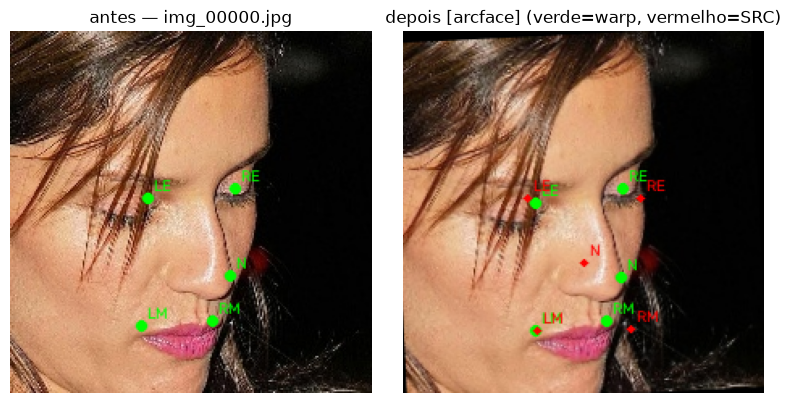

img_00000.jpg [arcface]: erro médio landmarks→SRC = 12.175 px


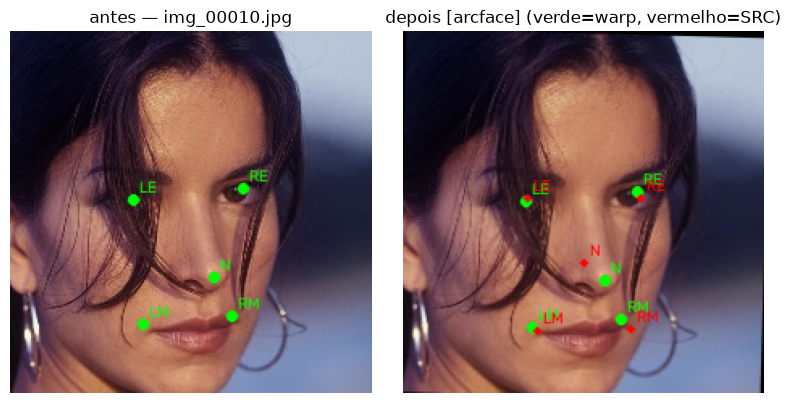

img_00010.jpg [arcface]: erro médio landmarks→SRC = 7.004 px


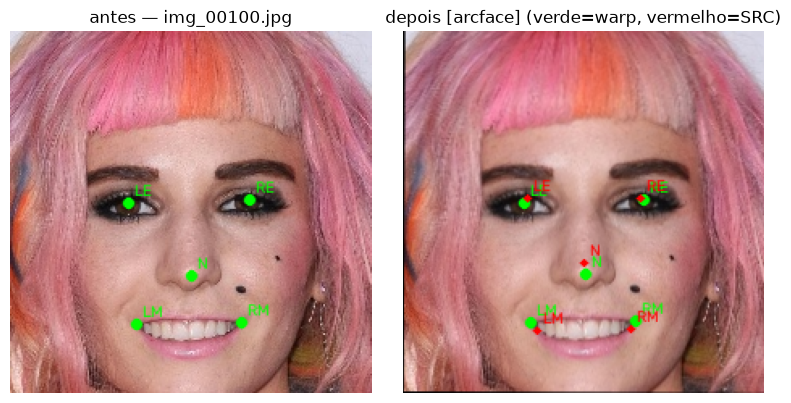

img_00100.jpg [arcface]: erro médio landmarks→SRC = 4.825 px


In [3]:
detector = get_default_detector(ctx_id=CTX_ID, det_thresh=DET_THRESH)

EXAMPLE_NAMES = ["img_00000.jpg", "img_00010.jpg", "img_00100.jpg"]
example_paths = [INPUT_DIR / name for name in EXAMPLE_NAMES]

print(f"Validando com TEMPLATE_NAME={TEMPLATE_NAME}")
for p in example_paths:
    if not p.exists():
        print(f"Arquivo ausente: {p}")
        continue
    plot_before_after(p, detector)


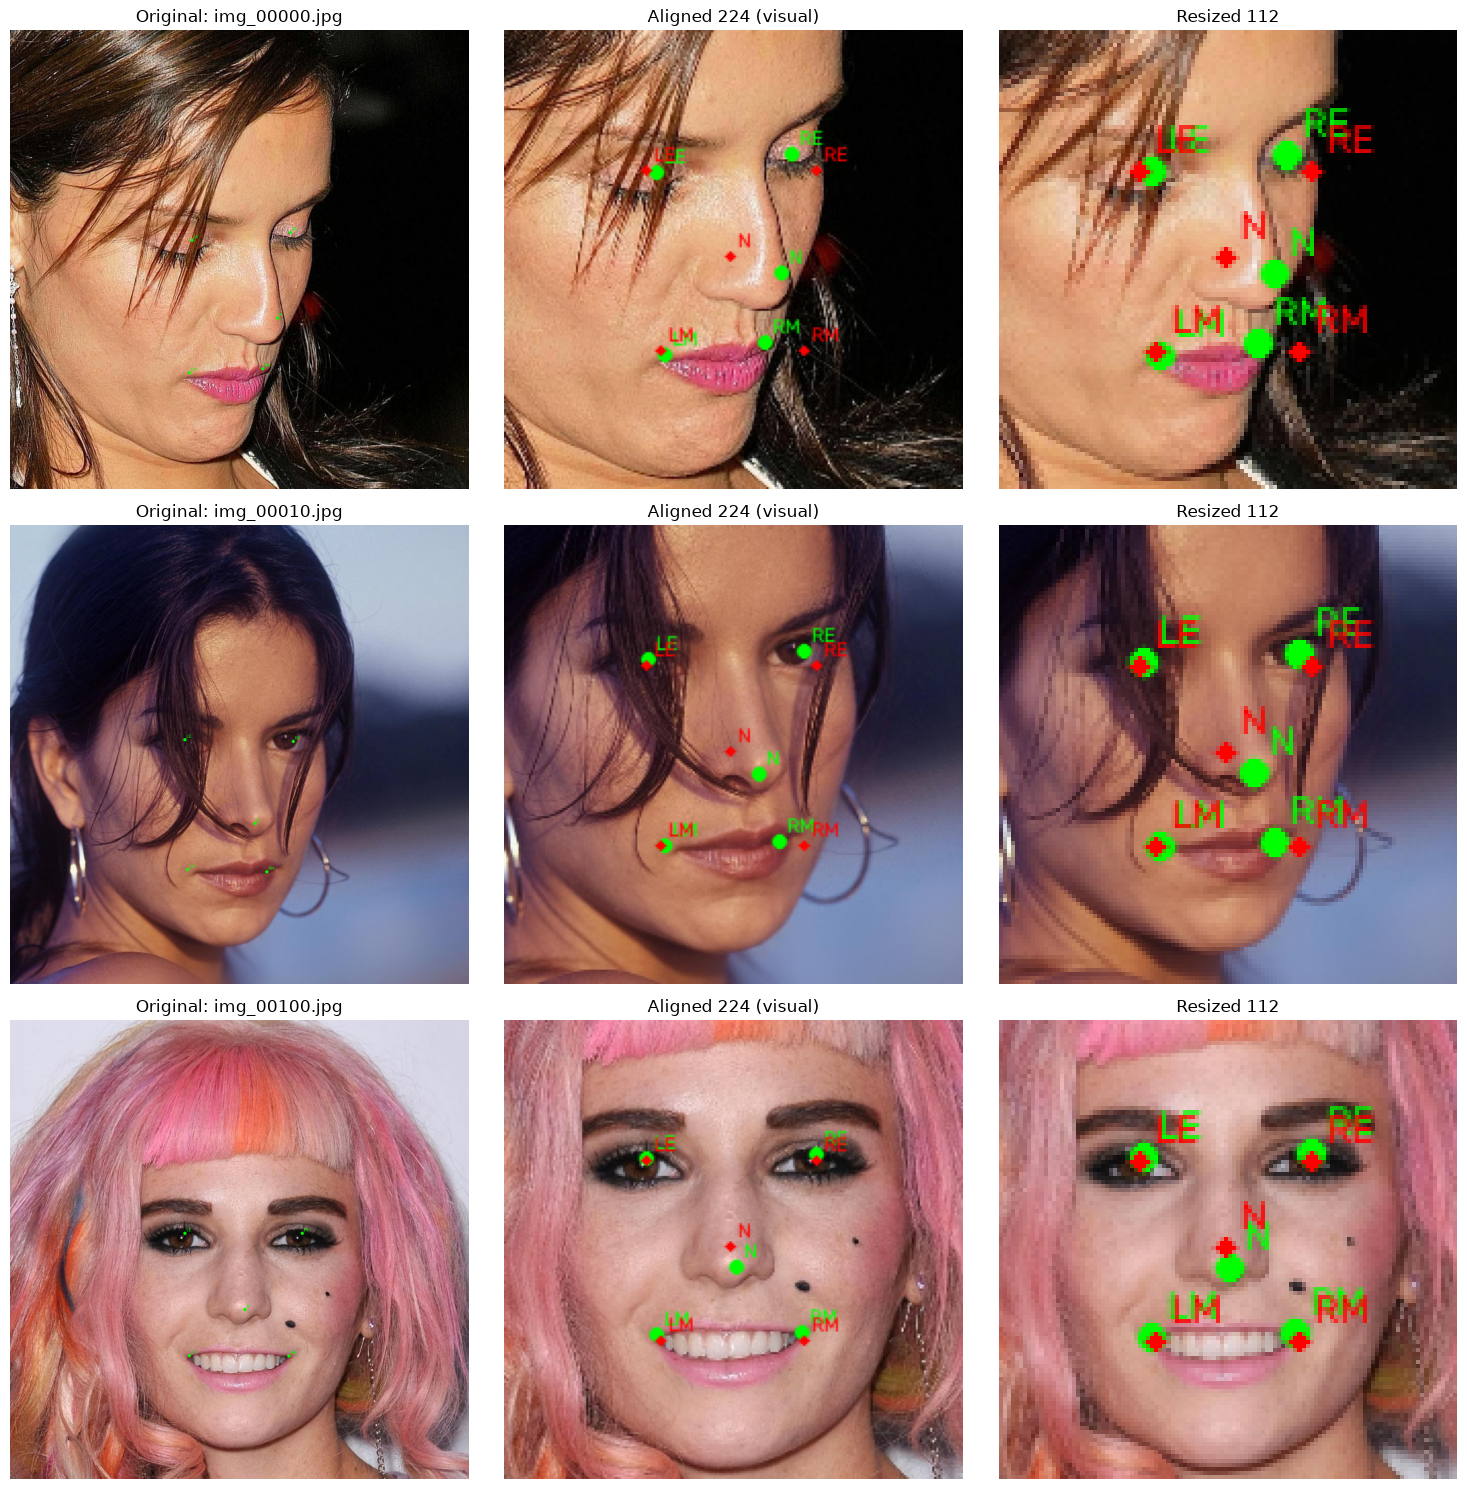

In [ ]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# Bring back your INPUT_DIR definition from the notebook
INPUT_DIR = Path("/mnt/study-data/dcarvalho/datasets/celebahq")

# 1. Join the filenames to the directory path
sample_images = [
    INPUT_DIR / "img_00000.jpg", 
    INPUT_DIR / "img_00010.jpg", 
    INPUT_DIR / "img_00100.jpg"
]

template_name = "visual" 

fig, axes = plt.subplots(3, 2, figsize=(10, 15))

for i, img_path in enumerate(sample_images):
    # str() converts the Path object so OpenCV can read it
    bgr_img = cv2.imread(str(img_path))
    
    if bgr_img is None: 
        print(f"Error: Could not read {img_path}")
        # Hide empty axes if image is missing
        axes[i, 0].axis("off")
        axes[i, 1].axis("off")
        continue

    # 2. Run your alignment helper
    pack, reason = align_to_template(bgr_img, detector, template=template_name)

    if pack is None:
        axes[i, 0].set_title(f"Failed: {reason}")
        axes[i, 0].axis("off")
        axes[i, 1].axis("off")
        continue

    aligned_img, lm_before, lm_after, dst_pts = pack

    # 3. Draw landmarks (Green = Detected, Red = Target Template)
    vis_before = draw_landmarks(bgr_img, lm_before, color=(0, 255, 0))
    vis_after = draw_landmarks(aligned_img, lm_after, color=(0, 255, 0))
    vis_after = draw_landmarks(vis_after, dst_pts, color=(0, 0, 255), radius=2)

    # 4. Plot to grid
    axes[i, 0].imshow(bgr_to_rgb(vis_before))
    axes[i, 0].set_title(f"Original: {img_path.name}") 
    axes[i, 0].axis("off") 

    axes[i, 1].imshow(bgr_to_rgb(vis_after))
    axes[i, 1].set_title(f"Aligned ({template_name})")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

## Comparação lado a lado — `arcface` vs `visual` (opcional)

Independente de `TEMPLATE_NAME`. Útil para decidir se vale gerar um segundo
dataset (`celebahq_pp_norm_visual`) no futuro.


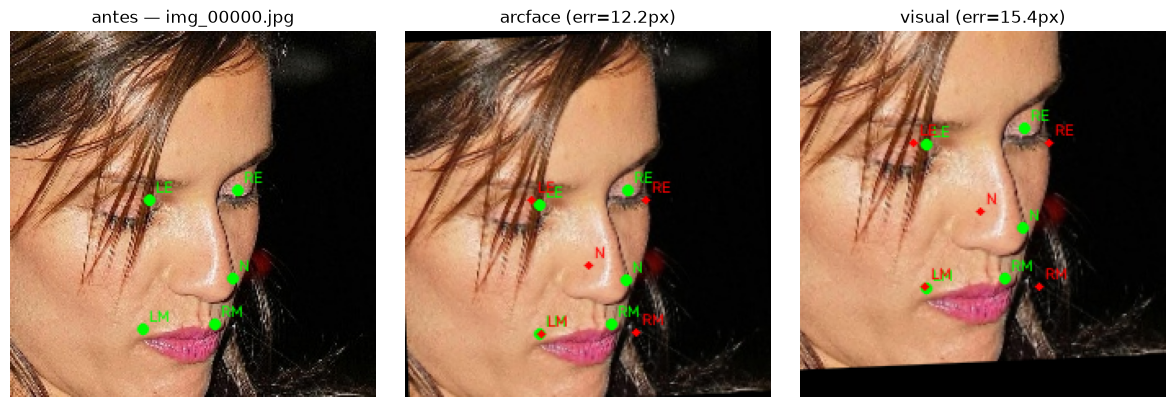

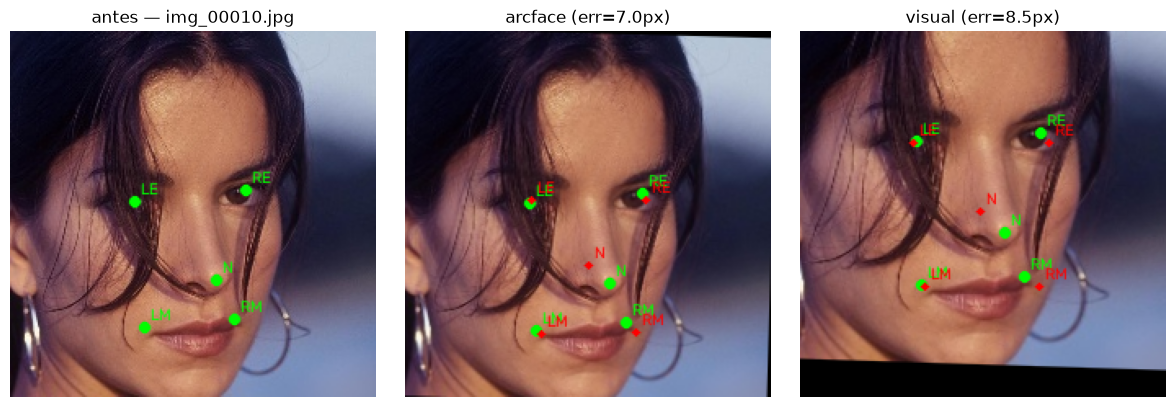

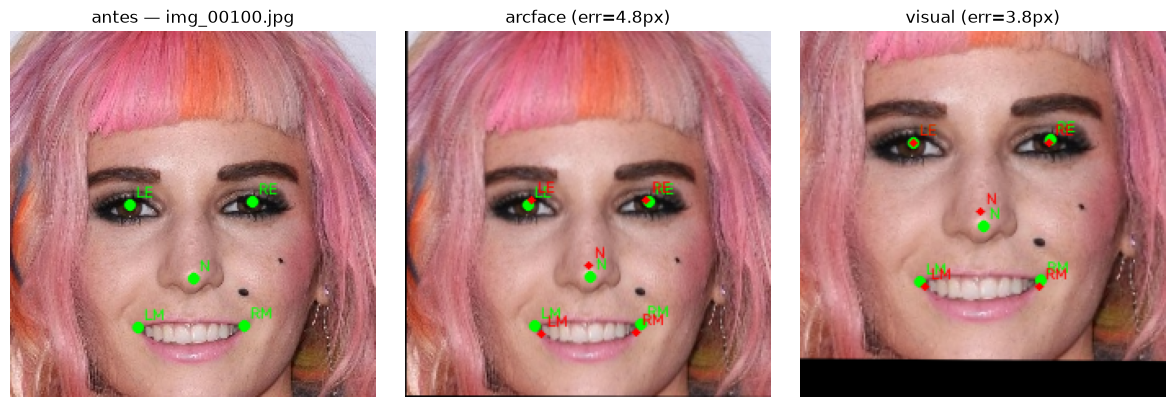

In [19]:
for p in example_paths:
    if not p.exists():
        print(f"Arquivo ausente: {p}")
        continue
    plot_compare_templates(p, detector)


## Batch completo

⚠️ Rodar **somente após** confirmar a validação visual.
Não executar automaticamente pelo agente.

Usa `TEMPLATE_NAME` / `OUT_DIR` da célula de setup:
- `arcface` → `celebahq_pp_norm`
- `visual` → `celebahq_pp_norm_visual`


In [ ]:
# ⚠️ Confirme a validação visual antes de executar esta célula.

OUT_DIR.mkdir(parents=True, exist_ok=True)

input_files = sorted(
    p for p in INPUT_DIR.iterdir() if p.suffix.lower() in VALID_EXT
)
print(f"TEMPLATE_NAME={TEMPLATE_NAME}")
print(f"OUT_DIR={OUT_DIR}")
print(f"Imagens de entrada: {len(input_files)}")

ok = 0
discarded_no_face = 0
discarded_affine = 0
discarded_read_error = 0

for src_path in tqdm(input_files, desc=f"Norm [{TEMPLATE_NAME}]"):
    try:
        bgr = _to_bgr_uint8(src_path)
    except (FileNotFoundError, OSError, ValueError, TypeError):
        discarded_read_error += 1
        continue

    pack, reason = align_to_template(bgr, detector, template=TEMPLATE_NAME)
    if pack is None:
        if reason == "no_face":
            discarded_no_face += 1
        else:
            discarded_affine += 1
        continue

    aligned, *_rest = pack
    out_path = OUT_DIR / src_path.name
    cv2.imwrite(
        str(out_path),
        aligned,
        [int(cv2.IMWRITE_JPEG_QUALITY), JPEG_QUALITY],
    )
    ok += 1

discarded = discarded_no_face + discarded_affine + discarded_read_error
total = len(input_files)
print("\n=== Resumo ===")
print(f"template:             {TEMPLATE_NAME}")
print(f"processadas (ok):     {ok}")
print(f"descartadas (total):  {discarded}")
print(f"  sem face:           {discarded_no_face}")
print(f"  affine falhou:      {discarded_affine}")
print(f"  erro de leitura:    {discarded_read_error}")
print(f"taxa de descarte:     {100.0 * discarded / max(total, 1):.3f}%")
print(
    f"arquivos em OUT_DIR:  "
    f"{sum(1 for p in OUT_DIR.iterdir() if p.suffix.lower() in VALID_EXT)}"
)
print(f"OUT_DIR: {OUT_DIR}")


## Sanity check — `FaceImageFolder`


In [ ]:
from data.dataset import FaceImageFolder

dataset = FaceImageFolder(OUT_DIR, image_size=IMAGE_SIZE)
print(f"FaceImageFolder carregou {len(dataset)} imagens de {OUT_DIR}")
x, path = dataset[0]
print(f"sample: shape={tuple(x.shape)}, path={path}")


## Item 2 — Normalização LFW (center crop 256→224 + landmarks)

Mesmos helpers/`TEMPLATE_NAME` da seção CelebA-HQ.

**Crop:** se a imagem for 256×256, corta o centro 224×224 **sem resize**.
Se já for 224×224 (caso atual de `faces_train`/`faces_test`), o crop é identidade
e apenas o alinhamento por landmarks é aplicado.

**Saída:** `/mnt/study-data/dcarvalho/datasets/lfw_norm/{faces_train,faces_test}`  
(preserva splits; `FaceImageFolder` aceita via `rglob`).

⚠️ Batch só após validar os 3 exemplos.


In [ ]:
# Paths LFW (já preprocessados no projeto: faces_* em 224×224)
LFW_ROOT = Path("/mnt/study-data/dcarvalho/datasets/lfw")
LFW_SPLITS = ("faces_train", "faces_test")
LFW_OUT_ROOT = Path("/mnt/study-data/dcarvalho/datasets/lfw_norm")

# Usa o mesmo TEMPLATE_NAME do setup (default arcface)
print(f"LFW_ROOT={LFW_ROOT}")
print(f"LFW_OUT_ROOT={LFW_OUT_ROOT}")
print(f"TEMPLATE_NAME={TEMPLATE_NAME}")
for split in LFW_SPLITS:
    n = sum(1 for p in (LFW_ROOT / split).iterdir() if p.suffix.lower() in VALID_EXT)
    print(f"  {split}: {n} imagens")



In [ ]:
def center_crop_to(bgr: np.ndarray, size: int = IMAGE_SIZE) -> np.ndarray:
    """Center crop HxW → size×size sem resize. Se já size×size, devolve cópia."""
    h, w = bgr.shape[:2]
    if h == size and w == size:
        return bgr
    if h < size or w < size:
        raise ValueError(f"Imagem {w}x{h} menor que crop {size}x{size}")
    y0 = (h - size) // 2
    x0 = (w - size) // 2
    return bgr[y0 : y0 + size, x0 : x0 + size]


def load_lfw_bgr(path) -> np.ndarray:
    """Lê imagem LFW e aplica center crop para IMAGE_SIZE."""
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None:
        raise FileNotFoundError(path)
    return center_crop_to(bgr, IMAGE_SIZE)


def plot_before_after_lfw(path, detector, *, template=None, show_template=True):
    """Como plot_before_after, mas com center crop prévio."""
    path = Path(path)
    dst, tname = resolve_template(template)
    try:
        bgr = load_lfw_bgr(path)
    except (FileNotFoundError, ValueError) as exc:
        print(f"Falha ao carregar/crop: {path.name}: {exc}")
        return None

    pack, reason = align_to_template(bgr, detector, template=dst)
    if pack is None:
        print(f"Falha ao alinhar ({reason}): {path.name}")
        return None

    aligned, lm_before, lm_after, dst_pts = pack
    before_vis = draw_landmarks(bgr, lm_before, color=(0, 255, 0))
    after_vis = draw_landmarks(aligned, lm_after, color=(0, 255, 0))
    if show_template:
        after_vis = draw_landmarks(after_vis, dst_pts, color=(0, 0, 255), radius=2)

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(bgr_to_rgb(before_vis))
    axes[0].set_title(f"após crop — {path.name}")
    axes[0].axis("off")
    axes[1].imshow(bgr_to_rgb(after_vis))
    axes[1].set_title(f"depois [{tname}]")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()

    err = np.linalg.norm(lm_after - dst_pts, axis=1).mean()
    print(f"{path.name} [{tname}]: erro médio = {err:.3f} px | shape_in_crop={bgr.shape[:2]}")
    return pack


print("Helpers LFW: center_crop_to, load_lfw_bgr, plot_before_after_lfw")



### Validação visual LFW — 3 imagens

Confirme o alinhamento antes do batch. Imagens atuais em `faces_train` já são 224×224
(crop identidade); se a fonte for 256×256, o crop central é aplicado primeiro.


In [ ]:
# 3 exemplos do faces_train
lfw_train_files = sorted(
    p for p in (LFW_ROOT / "faces_train").iterdir() if p.suffix.lower() in VALID_EXT
)
LFW_EXAMPLES = lfw_train_files[:3]
print(f"Exemplos LFW ({len(LFW_EXAMPLES)}): {[p.name for p in LFW_EXAMPLES]}")
print(f"TEMPLATE_NAME={TEMPLATE_NAME}")

for p in LFW_EXAMPLES:
    plot_before_after_lfw(p, detector, template=TEMPLATE_NAME)



### Batch LFW completo → `lfw_norm`

⚠️ Rodar **somente após** confirmar os 3 exemplos.
Não executar automaticamente pelo agente.


In [ ]:
# ⚠️ Confirme a validação visual LFW antes de executar.

LFW_OUT_ROOT.mkdir(parents=True, exist_ok=True)

ok = 0
discarded_no_face = 0
discarded_affine = 0
discarded_read_error = 0
discarded_crop = 0
total = 0

for split in LFW_SPLITS:
    src_dir = LFW_ROOT / split
    dst_dir = LFW_OUT_ROOT / split
    dst_dir.mkdir(parents=True, exist_ok=True)
    files = sorted(p for p in src_dir.iterdir() if p.suffix.lower() in VALID_EXT)
    print(f"=== {split}: {len(files)} arquivos → {dst_dir} ===")

    for src_path in tqdm(files, desc=f"LFW [{split}/{TEMPLATE_NAME}]"):
        total += 1
        try:
            bgr = load_lfw_bgr(src_path)
        except FileNotFoundError:
            discarded_read_error += 1
            continue
        except ValueError:
            discarded_crop += 1
            continue

        pack, reason = align_to_template(bgr, detector, template=TEMPLATE_NAME)
        if pack is None:
            if reason == "no_face":
                discarded_no_face += 1
            else:
                discarded_affine += 1
            continue

        aligned, *_ = pack
        cv2.imwrite(
            str(dst_dir / src_path.name),
            aligned,
            [int(cv2.IMWRITE_JPEG_QUALITY), JPEG_QUALITY],
        )
        ok += 1

discarded = discarded_no_face + discarded_affine + discarded_read_error + discarded_crop
print("\n=== Resumo LFW ===")
print(f"TEMPLATE_NAME={TEMPLATE_NAME}")
print(f"processadas (ok):     {ok}")
print(f"descartadas (total):  {discarded}")
print(f"  sem face:           {discarded_no_face}")
print(f"  affine falhou:      {discarded_affine}")
print(f"  erro de leitura:    {discarded_read_error}")
print(f"  crop inválido:      {discarded_crop}")
print(f"taxa de descarte:     {100.0 * discarded / max(total, 1):.3f}%")
n_out = sum(
    1
    for split in LFW_SPLITS
    for p in (LFW_OUT_ROOT / split).rglob("*")
    if p.suffix.lower() in VALID_EXT
)
print(f"arquivos em LFW_OUT_ROOT: {n_out}")
print(f"LFW_OUT_ROOT: {LFW_OUT_ROOT}")



### Sanity check LFW — `FaceImageFolder`


In [ ]:
from data.dataset import FaceImageFolder

# Pode apontar para um split ou para a raiz (rglob)
lfw_ds = FaceImageFolder(LFW_OUT_ROOT / "faces_train", image_size=IMAGE_SIZE)
print(f"FaceImageFolder(faces_train) → {len(lfw_ds)} imagens")
x, path = lfw_ds[0]
print(f"sample: shape={tuple(x.shape)}, path={path}")



## Teste / visualização — template `visual` (3 exemplos)

Célula **somente para inspeção**: força o template externo `visual` (olhos ~y=68),
independente de `TEMPLATE_NAME`. Não altera o batch default (`arcface`).

Esperado: face mais alta/maior no canvas e possível faixa preta na base
(`BORDER_CONSTANT`).


In [ ]:
print("Visualização com template='visual' (não muda TEMPLATE_NAME nem OUT_DIR)")
print(f"TEMPLATE_NAME atual do setup: {TEMPLATE_NAME}")

for p in example_paths:
    if not p.exists():
        print(f"Arquivo ausente: {p}")
        continue
    plot_before_after(p, detector, template="visual")

